# 01 — Analyse exploratoire : ETTh1

**Dataset** : Electricity Transformer Temperature (hourly), 2016-07 → 2018-06  
**Target principale (LTSF)** : `OT` (Oil Temperature)  
**Objectif** : comprendre la structure du signal avant de choisir les modèles.

Ce notebook couvre :
1. Chargement et statistiques descriptives
2. Visualisation temporelle des 7 variables
3. Valeurs manquantes et outliers
4. Analyse de stationnarité (ADF)
5. Décomposition STL (tendance + saisonnalité)
6. Autocorrélation (ACF / PACF)
7. Analyse fréquentielle (FFT)
8. Corrélations inter-variables

In [1]:
import sys, os
sys.path.append(os.path.abspath('..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.tsa.seasonal import STL

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['figure.dpi'] = 100

## 1. Chargement et statistiques descriptives

In [2]:
df = pd.read_csv('../data/raw/ETTh1.csv')
df['date'] = pd.to_datetime(df['date'])
df = df.set_index('date')

print(f'Shape       : {df.shape}')
print(f'Periode     : {df.index.min()} -> {df.index.max()}')
print(f'Frequence   : {pd.infer_freq(df.index)}')
print(f'Variables   : {list(df.columns)}')
df.head()

Shape       : (17420, 7)
Periode     : 2016-07-01 00:00:00 -> 2018-06-26 19:00:00
Frequence   : h
Variables   : ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']


,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
date,,,,,,,
2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001
2016-07-01 02:00:00,5.157,1.741,1.279,0.355,3.777,1.218,27.787001
2016-07-01 03:00:00,5.090,1.942,1.279,0.391,3.807,1.279,25.044001
2016-07-01 04:00:00,5.358,1.942,1.492,0.462,3.868,1.279,21.948000


In [3]:
df.describe().round(3)

,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
count,17420.000,17420.000,17420.000,17420.000,17420.000,17420.000,17420.000
mean,7.375,2.242,4.300,0.882,3.066,0.857,13.325
std,7.068,2.042,6.827,1.809,1.165,0.600,8.567
min,-22.706,-4.756,-25.088,-5.934,-1.188,-1.371,-4.080
25%,5.827,0.737,3.296,-0.284,2.315,0.670,6.964
50%,8.774,2.210,5.970,0.959,2.833,0.975,11.396
75%,11.788,3.684,8.635,2.203,3.625,1.218,18.079
max,23.644,10.114,17.341,7.747,8.498,3.046,46.007


**Lecture** : 17 420 pas horaires, aucune donnée manquante (à vérifier ci-dessous), 7 variables de charge électrique (H/M/L × UseFul/UseLess) et la température d'huile `OT`.

## 2. Visualisation temporelle des 7 variables

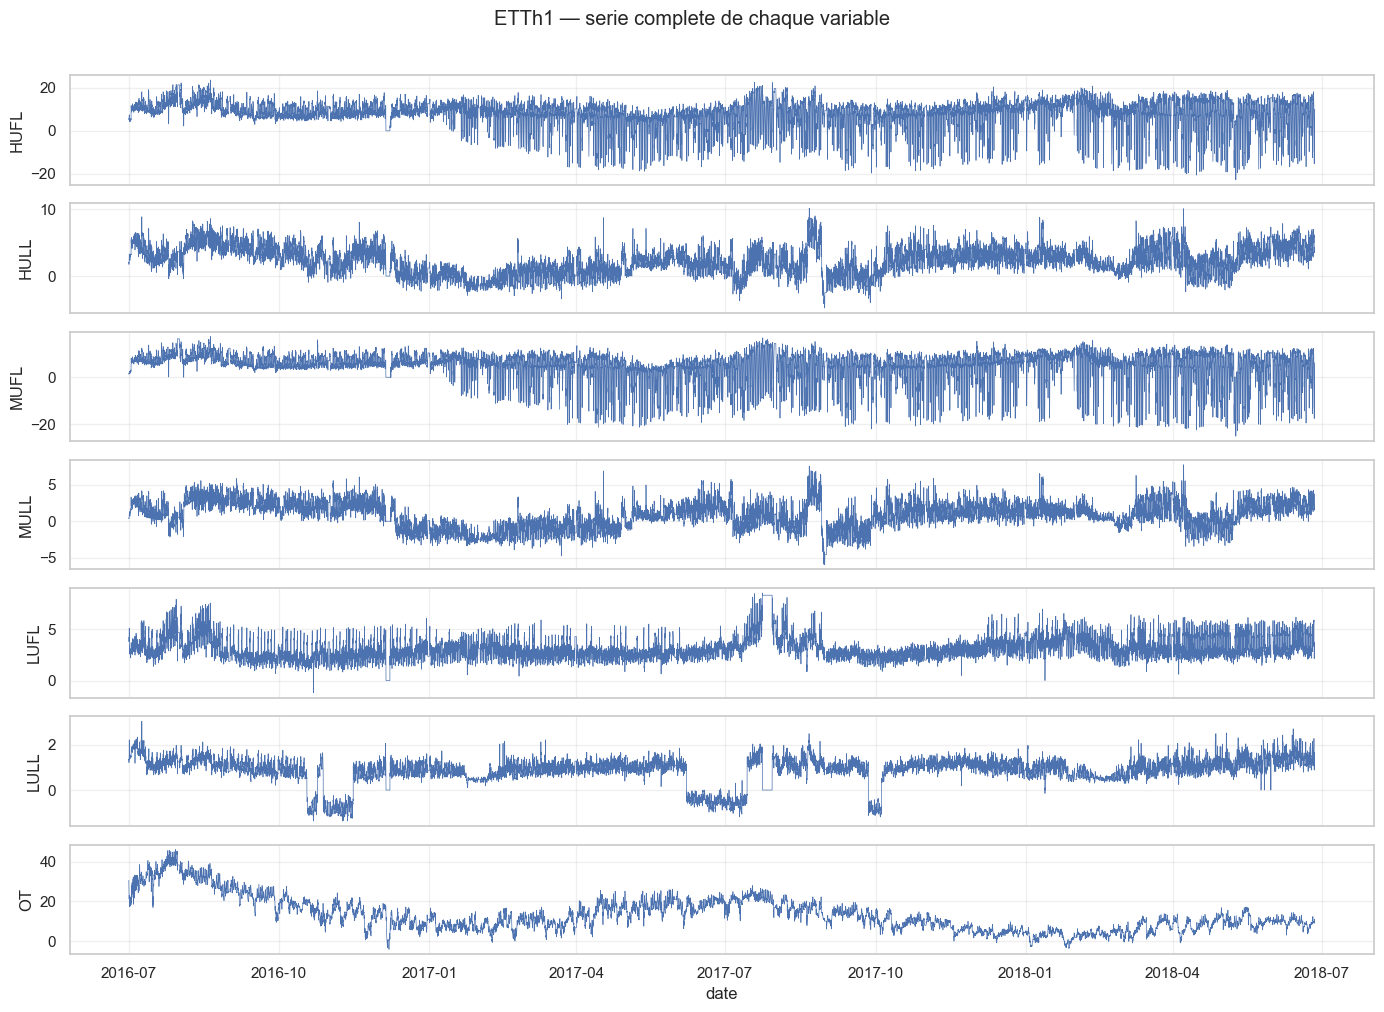

In [4]:
fig, axes = plt.subplots(len(df.columns), 1, figsize=(14, 10), sharex=True)
for ax, col in zip(axes, df.columns):
    ax.plot(df.index, df[col], linewidth=0.5)
    ax.set_ylabel(col)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel('date')
fig.suptitle('ETTh1 — serie complete de chaque variable', y=1.01)
plt.tight_layout();

**Observations** :
- `OT` présente une saisonnalité annuelle claire (été chaud → huile chaude).
- Les charges (H/M/L UFL/ULL) montrent une saisonnalité journalière et hebdomadaire plus marquée.
- Pas de rupture structurelle majeure ni de trend monotone sur 2 ans.

## 3. Valeurs manquantes et outliers

In [5]:
print('Valeurs manquantes par colonne :')
print(df.isna().sum())
print(f'\nDoublons sur date : {df.index.duplicated().sum()}')

Valeurs manquantes par colonne :
HUFL    0
HULL    0
MUFL    0
MULL    0
LUFL    0
LULL    0
OT      0
dtype: int64

Doublons sur date : 0


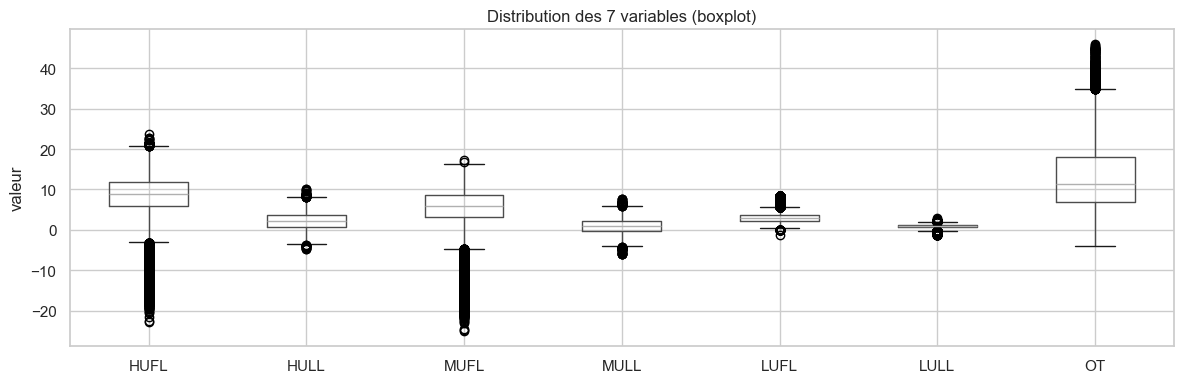

In [6]:
fig, ax = plt.subplots(figsize=(12, 4))
df.boxplot(ax=ax)
ax.set_title('Distribution des 7 variables (boxplot)')
ax.set_ylabel('valeur')
plt.tight_layout();

## 4. Stationnarité — test ADF sur OT

In [7]:
def adf_report(series, name):
    stat, pval, lags, nobs, crit, _ = adfuller(series.dropna(), autolag='AIC')
    verdict = 'STATIONNAIRE (reject H0)' if pval < 0.05 else 'NON stationnaire'
    print(f'{name:6s} | ADF={stat:+.3f}  p-value={pval:.4f}  -> {verdict}')

for col in df.columns:
    adf_report(df[col], col)

HUFL   | ADF=-8.551  p-value=0.0000  -> STATIONNAIRE (reject H0)


HULL   | ADF=-5.169  p-value=0.0000  -> STATIONNAIRE (reject H0)


MUFL   | ADF=-8.621  p-value=0.0000  -> STATIONNAIRE (reject H0)


MULL   | ADF=-4.964  p-value=0.0000  -> STATIONNAIRE (reject H0)


LUFL   | ADF=-5.797  p-value=0.0000  -> STATIONNAIRE (reject H0)


LULL   | ADF=-4.773  p-value=0.0001  -> STATIONNAIRE (reject H0)


OT     | ADF=-3.488  p-value=0.0083  -> STATIONNAIRE (reject H0)


**Lecture** : la plupart des séries sont stationnaires (p-value < 0.05), condition nécessaire pour les baselines ARIMA. `OT` l'est aussi : pas besoin de différenciation.

## 5. Décomposition STL de OT

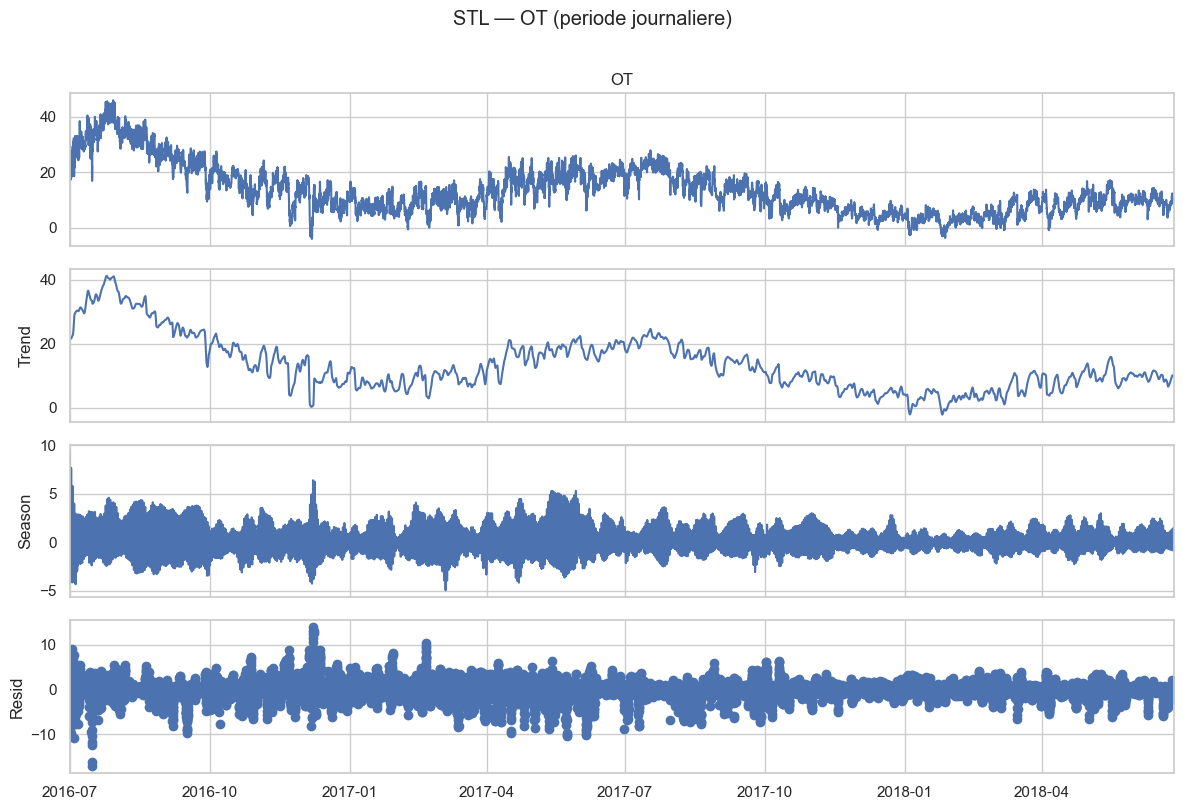

In [8]:
stl = STL(df['OT'], period=24, robust=True).fit()
fig = stl.plot()
fig.set_size_inches(12, 8)
fig.suptitle('STL — OT (periode journaliere)', y=1.01)
plt.tight_layout();

**Lecture** : saisonnalité journalière modérée sur OT. La **tendance** capte l'onde annuelle (plus visible en zoomant).

## 6. Autocorrélation — ACF et PACF sur OT

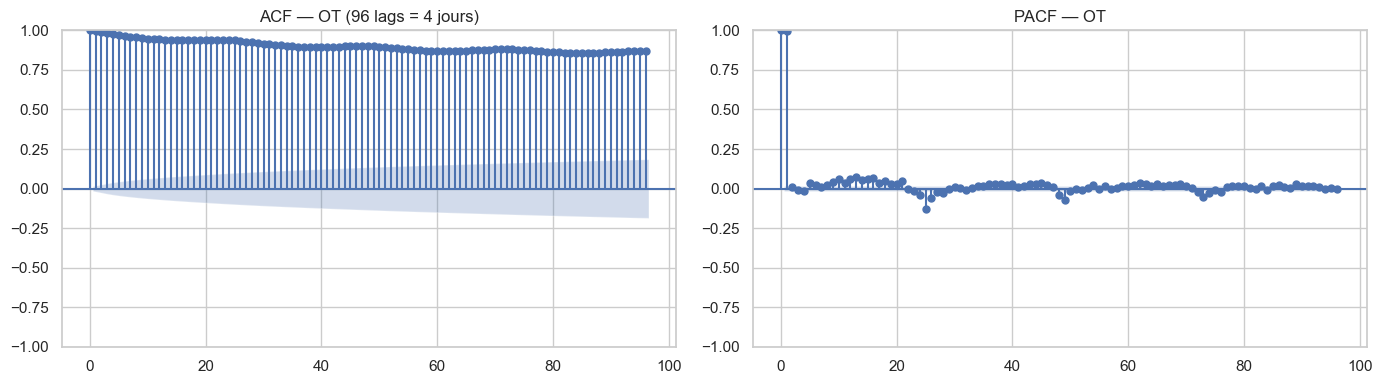

In [9]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(df['OT'], lags=96, ax=axes[0])
axes[0].set_title('ACF — OT (96 lags = 4 jours)')
plot_pacf(df['OT'], lags=96, ax=axes[1], method='ywm')
axes[1].set_title('PACF — OT')
plt.tight_layout();

**Lecture** : l'ACF décroît très lentement — mémoire longue classique des séries de température. La PACF se coupe rapidement : les premiers lags portent l'information prédictive.

## 7. Analyse fréquentielle (FFT)

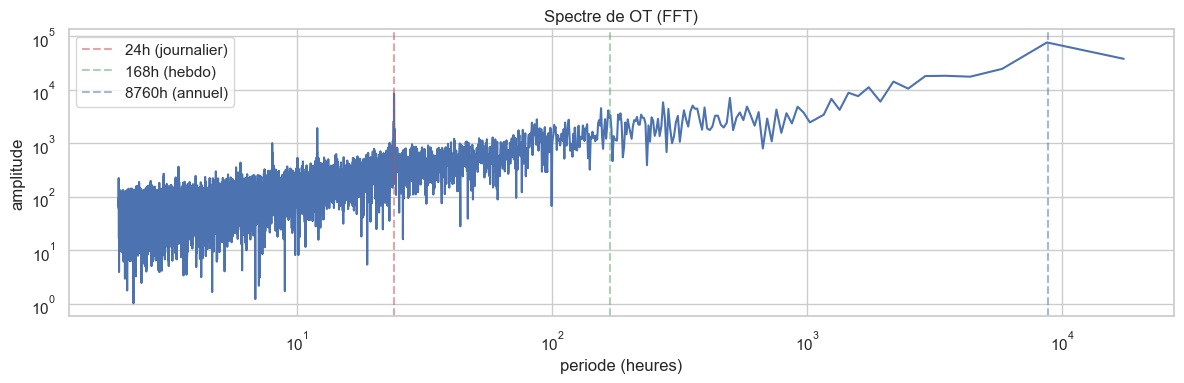

In [10]:
ot = df['OT'].values - df['OT'].mean()
fft_vals = np.fft.rfft(ot)
freqs = np.fft.rfftfreq(len(ot), d=1.0)   # d = 1 heure
amp = np.abs(fft_vals)

periods_h = 1 / freqs[1:]                 # periodes en heures (on skip la freq 0)
amp_main  = amp[1:]

fig, ax = plt.subplots(figsize=(12, 4))
ax.loglog(periods_h, amp_main)
ax.axvline(24,    color='r', ls='--', alpha=0.5, label='24h (journalier)')
ax.axvline(24*7,  color='g', ls='--', alpha=0.5, label='168h (hebdo)')
ax.axvline(24*365, color='b', ls='--', alpha=0.5, label='8760h (annuel)')
ax.set_xlabel('periode (heures)')
ax.set_ylabel('amplitude')
ax.set_title('Spectre de OT (FFT)')
ax.legend()
plt.tight_layout();

**Lecture** : pics clairs aux périodes journalière et annuelle. L'horizon 96 (4 jours) couvre 4 cycles journaliers — pertinent pour les modèles comme Autoformer qui exploitent explicitement la saisonnalité.

## 8. Corrélations inter-variables

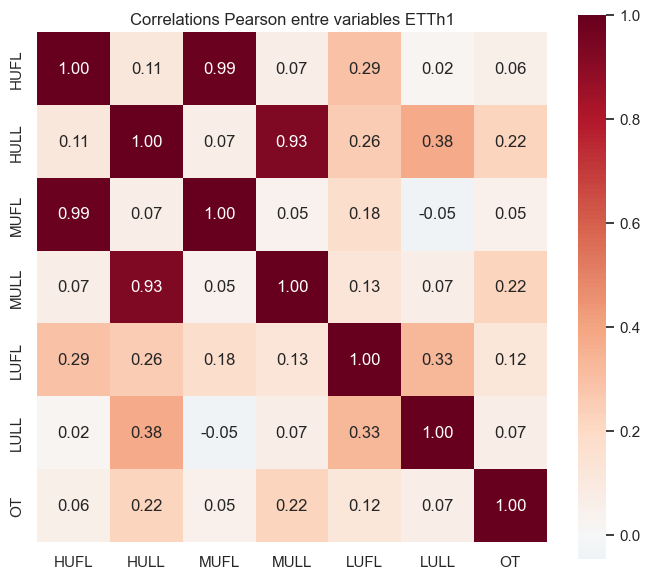

In [11]:
corr = df.corr()
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, square=True, ax=ax)
ax.set_title('Correlations Pearson entre variables ETTh1')
plt.tight_layout();

**Lecture** : les charges Useful/Useless au même niveau (H/M/L) sont très corrélées → redondance. `OT` est faiblement corrélée aux charges **instantanées** mais réagit avec un lag (physique : la chaleur s'accumule).

---

## Conclusions pour le choix des modèles

| Observation | Implication |
|---|---|
| Saisonnalités multiples (24h, 7j, 365j) | ✅ Autoformer / FEDformer (décomposition explicite) |
| Mémoire longue (ACF décroît lentement) | ✅ Attention bien adaptée, Transformer vanilla acceptable |
| Variables inter-corrélées | ⚠️ PatchTST (channel-independent) peut y perdre vs modèles multivariés |
| Pas de missing, pas d'outliers extrêmes | ✅ Prétraitement minimal |
| Série stationnaire | ✅ Baseline ARIMA directement comparable |

**Suite** : `02_baseline.ipynb` — Naïve, DLinear, ARIMA sur ETTh1.